# Build Tracker — AI Agent Response Evaluator

Working doc for the assignment build (not a deliverable — see `outputs/reports/` for the
submitted evaluation report). Run the cell below any time to see an up-to-date visual of
progress: toggle a step's `True`/`False` in the `STEPS` list as you finish it, then re-run
the cell.

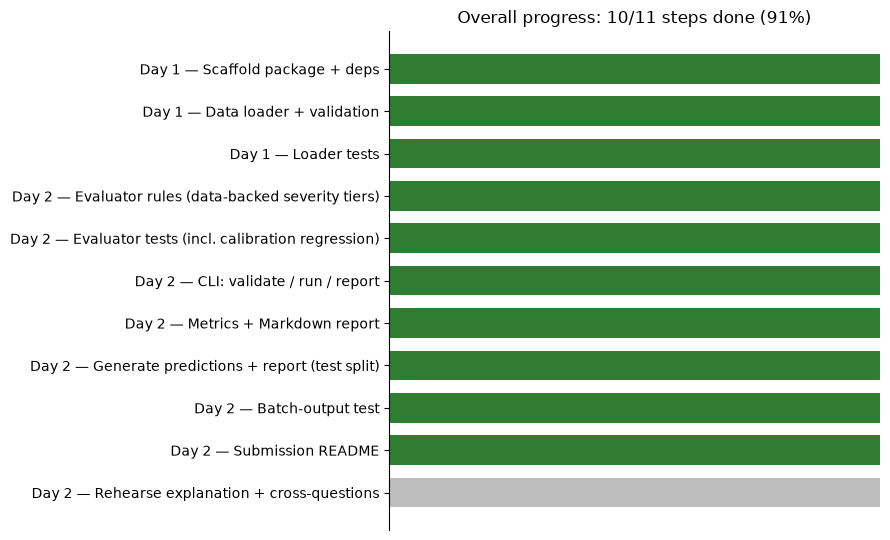

In [3]:
import matplotlib.pyplot as plt

# Day label, step name, done flag — update `done` as you complete each step, then re-run this cell.
STEPS = [
    ("Day 1", "Scaffold package + deps", True),
    ("Day 1", "Data loader + validation", True),
    ("Day 1", "Loader tests", True),
    ("Day 2", "Evaluator rules (data-backed severity tiers)", True),
    ("Day 2", "Evaluator tests (incl. calibration regression)", True),
    ("Day 2", "CLI: validate / run / report", True),
    ("Day 2", "Metrics + Markdown report", True),
    ("Day 2", "Generate predictions + report (test split)", True),
    ("Day 2", "Batch-output test", True),
    ("Day 2", "Submission README", True),
    ("Day 2", "Rehearse explanation + cross-questions", False),
]

done_count = sum(done for _, _, done in STEPS)
total_count = len(STEPS)

labels = [f"{day} — {name}" for day, name, _ in STEPS]
colors = ["#2e7d32" if done else "#bdbdbd" for _, _, done in STEPS]
y_pos = range(len(STEPS))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(y_pos, [1] * len(STEPS), color=colors, height=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xticks([])
for spine in ("top", "right", "bottom"):
    ax.spines[spine].set_visible(False)
ax.set_title(f"Overall progress: {done_count}/{total_count} steps done ({done_count/total_count:.0%})")
plt.tight_layout()
plt.show()

## Required work (README) at a glance

| # | Item | Status | Where |
| - | --- | --- | --- |
| 1 | Data loading & validation | Done | `src/evaluator/loader.py`, `src/evaluator/models.py` |
| 2 | Evaluation logic (deterministic rules) | Not started | — |
| 3 | Batch output (one result per case) | Not started | — |
| 4 | Evaluation report (metrics + error examples) | Not started | — |
| 5 | Tests | Partial (loader only) | `tests/test_loader.py` |

## Deliverables checklist (README "Deliverables")

- [x] Source code (loader so far)
- [x] Dependency file — `pyproject.toml` (no runtime deps, pytest for dev)
- [ ] Install/run instructions (submission README)
- [x] Automated tests + run command (loader tests only so far)
- [ ] Generated predictions for the 36 test records
- [ ] Evaluation report (Markdown)
- [ ] Assumptions/limitations/next-steps note

## Detailed task status

### Day 1 — Foundation (done)

- [x] Scaffold package + `pyproject.toml`
- [x] Data loader + validation (case_id uniqueness, enum checks, state_json fallback,
      malformed-JSON handling, no silent row skipping)
- [x] Loader tests — 6 passing (valid row, state_json fallback priority, malformed
      JSON, duplicate case_id, invalid gold_verdict, full 48-row real file)

### Day 2 — Logic, CLI, metrics, polish (not started)

- [ ] Evaluator: 6 generic deterministic checks (authority/limit breach, unauthorized
      tool use, format compliance, escalation signals, groundedness mismatch, privacy
      disclosure) — designed against the 12 calibration examples, not yet built
- [ ] Evaluator tests (clear PASS case, clear policy/authority breach case)
- [ ] CLI: `validate` / `run` / `report` subcommands (argparse)
- [ ] Metrics: accuracy, macro F1, confusion matrix, precision/recall for
      `policy_violation`, MAE for `quality_score`
- [ ] Batch-output test (case_id preserved through the pipeline)
- [ ] Generate `outputs/predictions/*.json` + `outputs/reports/*.md` for the 36
      test-split records
- [ ] Submission README (approach, trade-offs, assumptions, limitations, what's next)
- [ ] Rehearse explaining each file + likely cross-questions

### Cut from scope

- Optional judge-framework extension — cut, not attempting given the time budget

## Time budget

- Day 1 (~1–1.5h): scaffold + loader + loader tests → **done, on budget**
- Day 2 (~4–5h): everything else above, in the listed order

Full design rationale and calibration-example notes are saved in repo memory
(`ai-agent-evaluator-assignment.md`) for continuity across sessions.